# 9 Линейная и логистическая регрессия

**Цель работы:** с помощью средств и библиотек языка программирования Python обучить модели линейной и логистической регрессии на основе выборки со сниженной размерностью.

**Выполнил:** ст.группы 24ВВИ1 Будников А.С.

## Теоретическая часть

### 1. Что такое линейная регрессия и какую задачу она решает?

Линейная регрессия это метод и алгоритм машинного обучения с учителем, который используется для прогнозирования количественной целевой переменной. Она предполагает линейную зависимость целевой переменной от входных признаков. В виде формулы:

(y - выход, x- вход, a и b - параметры)

\\(y=\sum a_i \cdot x_i+b\\)

Во время обучения алгоритм подбирает параметры так, чтобы у результирующей модели, разница между фактическим и предсказанным значением была минимальна, то есть минимизирует функцию потерь. Решает задачу регрессии, то есть восстановления непрерывной величины по набору исходных признаков.

### 2. Что такое логистическая регрессия и чем она принципиально отличается от линейной регрессии?

Логистическая регрессия это метод и алгоритм машинного обучения с учителем, который предсказывает вероятность пренадлежности объякта к классу. В отличие от линейной регрессии логистическая строит предполагает нелинейную зависимость на выходе, но по входу граница остается линейной, то есть модель все еще линейная, но приспособлена под классификацию. Для выхода может применяться сигмоида или softmax. Принципиальными отличиями являются: решаемая задача и выход в виде вероятности.

### 3. Почему линейная регрессия не подходит для задач классификации?

Линейная регрессия не подходит для задач классификации потому что ее устройство предназначено для предсказания вещественных чисел. Так, выходы не ограничиваются и могут выйти за логические пределы, например, уйти в отрицательные значения, что не имеет смысла. Не стоит забывать про эффект, при котором классы более близкие по числовым значениям трактуются моделью как более близкие в логическом смысле этого слова. Также здесь можно упомянуть, что прямая плохо разделяет классы, особенно при многоклассовом распределении.

### 4. Что означает: коэффициент модели регрессии; свободный член (intercept)?

Коэффициент при признаке x показывает "вес" признака, то есть насколько изменится предсказание при изменении этого признака; здесь знак трактуется как направление влияния, например, при минусе наблюдается обратная зависимость и признак будет меньше влиять на результат предсказания. Свободный член b отражает значение выхода при нулевых коэффициентах при признаке x. Он будто сдвигает линию разделения классов относительно начала координат, показывает изначальную отправную точку модели до влияния признаков.

### 5. Почему линейные модели применяются после масштабирования признаков?

Линейные модели как алгоритмы сильно зависят от масштаба. При разном масштабе признаков наиболее вероятно произойдет конфликт единиц измерения: признаки с меньшим масштабом будут доминировать над теми, что имеют больший, из за разности в числовых значениях. При введении дополнительного члена в виде регуляризации штраф будет применяться неравномерно к коэффициентам разных признакам, и опять же одни будут вытеснять другие при финальной оценке. В целом, так как работаем на компьютере нельзя забывать, что с меньшими числами - меньший шанс на переполнения и другие исключетельные ситуации. Ну и конечно при одинаковом масштабе признаков градиент ведет себя стабильнее.

## Практическая часть

## 2 & 2.1 Базовый уровень

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression 
from sklearn.linear_model import LogisticRegression

from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, f1_score, classification_report, confusion_matrix
)

import time

In [2]:
train_t = pd.read_csv('data/covtype-t.csv')
test_t = pd.read_csv('data/covtype-t-test.csv')

train = pd.read_csv('data/covtype-7-ss.csv')
test = pd.read_csv('data/covtype-7-test-ss.csv')

train_pca = pd.read_csv('data/train_bin44_pca2.csv')
test_pca = pd.read_csv('data/test_bin44_pca2.csv')

train_tt = pd.read_csv('data/covtype-7-s.csv')
test_tt = pd.read_csv('data/covtype-7-test-s.csv')
tt = pd.concat([train_tt, test_tt], ignore_index=True)

print(f'Train shape={train.shape}')
print(f'Test shape={test.shape}')
print()
print(f'PCA Train shape={train_pca.shape}')
print(f'PCA Test shape={test_pca.shape}')
print()

X_train = train.drop(columns=['Тип_лесного_покрова'])
y_train = train['Тип_лесного_покрова']
X_test = test.drop(columns=['Тип_лесного_покрова'])
y_test = test['Тип_лесного_покрова']

X_train_pca = train_pca.drop(columns=['Тип_лесного_покрова'])
y_train_pca = train_pca['Тип_лесного_покрова']
X_test_pca = test_pca.drop(columns=['Тип_лесного_покрова'])
y_test_pca = test_pca['Тип_лесного_покрова']

X_train_t = train_t.drop(columns=['Тип_лесного_покрова'])
y_train_t = train_t['Тип_лесного_покрова']
X_test_t = test_t.drop(columns=['Тип_лесного_покрова'])
y_test_t = test_t['Тип_лесного_покрова']

print(f'X_train={X_train.shape}\ty_train={y_train.shape}')
print(f'X_test={X_test.shape}\ty_test={y_test.shape}')
print()
print(f'X_train_pca={X_train_pca.shape}\ty_train_pca={y_train_pca.shape}')
print(f'X_test_pca={X_test_pca.shape}\ty_test_pca={y_test_pca.shape}')
print()
print(f'X_train_t={X_train_t.shape}\ty_train_t={y_train_t.shape}')
print(f'X_test_t={X_test_t.shape}\ty_test_t={y_test_t.shape}')

Train shape=(317254, 48)
Test shape=(116194, 48)

PCA Train shape=(317254, 47)
PCA Test shape=(116194, 47)

X_train=(317254, 47)	y_train=(317254,)
X_test=(116194, 47)	y_test=(116194,)

X_train_pca=(317254, 46)	y_train_pca=(317254,)
X_test_pca=(116194, 46)	y_test_pca=(116194,)

X_train_t=(317254, 54)	y_train_t=(317254,)
X_test_t=(116194, 54)	y_test_t=(116194,)


## Анализ

В качестве датасета используется [Forest Cover Types](https://www.kaggle.com/datasets/uciml/forest-cover-type-dataset/data).
Здесь содержатся данные о типах лесного покрова для территорий национального парка Рузвельта в Колорадо США. Каждая строка таблицы описывает один участок земли площадью 30×30 метров. Набор признаков включает информацию о типе дерева, степени затенения, расстоянии до близлежащих ориентиров (дорог и т. д.), типе почвы и местном рельефе.

Всего в датасете 581 012 записей и 55 столбцов, однако в результате проделанной работы количество строк значительно сократилось. Для удобства чтения столбцы были переименованы.

Расшифрока значений целевой переменной:

1. Ель/Пихра
2. Сосна скрученная
3. Сосна пондероза
4. Тополь/Ива
5. Осина
6. Дугласова пихта
7. Круммхольц

На текущем этапе датасет уже прошел этапы очистки, масштабирования и отбора признаков в работах 5,6 и 7 соответственно, а также сэмплинг. Отмечу, что с самого начала данные делим на обучающую, или тренировочную, и тестовую выборки.

В данной работе будем использовать 2 выборки. Первая - до выделения признаков и после отбора, вторая - после выделения признаков. Такой подход позволит оценить качество компонент, созданных в работе №8, и целесообразность применения метода PCA к используемому набору данных.

In [3]:
linr = LinearRegression()
start = time.time()
linr.fit(X_train, y_train)
time_linr = time.time() - start
print(f'Обученные параметры: b={linr.intercept_:.4f} a={linr.coef_[0]:.4f}')

y_pred_linr = linr.predict(X_test)
y_pred_linr

Обученные параметры: b=5.7295 a=-0.2401


array([2.84110947, 6.6553336 , 2.25346366, ..., 3.27949401, 2.17647473,
       1.02797745], shape=(116194,))

In [4]:
print('LinearRegression на 47 признаков:')
print(f'Время обучения: {time_linr} секунд')
print(f'  MAE: {mean_absolute_error(y_test, y_pred_linr)}')
print(f'  MSE: {mean_squared_error(y_test, y_pred_linr)}')
print(f'  R²:  {r2_score(y_test, y_pred_linr)}')
print(f'  Диапазон предсказаний: [{y_pred_linr.min()}; {y_pred_linr.max()}]')
print(f'  Допустимые классы: [{y_test.min()}; {y_test.max()}]')
out_share = ((y_pred_linr < 1) | (y_pred_linr > 7)).mean() * 100
print(f'  Доля предсказаний вне [1, 7]: {out_share}%')

LinearRegression на 47 признаков:
Время обучения: 1.6075623035430908 секунд
  MAE: 1.3863702381164351
  MSE: 2.9642853068807318
  R²:  -0.5198992371316797
  Диапазон предсказаний: [0.6792382216625947; 8.039304489103735]
  Допустимые классы: [1; 7]
  Доля предсказаний вне [1, 7]: 1.5508546052291856%


In [5]:
linr_pca = LinearRegression()
start_pca = time.time()
linr_pca.fit(X_train_pca, y_train_pca)
time_linr_pca = time.time() - start_pca
print(f'Обученные параметры: b={linr_pca.intercept_:.4f} a={linr_pca.coef_[0]:.4f}')
y_pred_linr_pca = linr_pca.predict(X_test_pca)
y_pred_linr_pca

Обученные параметры: b=5.9197 a=-0.6417


array([2.85959461, 6.64474654, 2.24974966, ..., 3.2785739 , 2.1840768 ,
       1.03931043], shape=(116194,))

In [6]:
print('LinearRegression на 46 признаках (с компонентами):')
print(f'Время обучения: {time_linr_pca} секунд')
print(f'  MAE: {mean_absolute_error(y_test_pca, y_pred_linr_pca)}')
print(f'  MSE: {mean_squared_error(y_test_pca, y_pred_linr_pca)}')
print(f'  R²:  {r2_score(y_test_pca, y_pred_linr_pca)}')
print(f'  Диапазон предсказаний: [{y_pred_linr_pca.min()}; {y_pred_linr_pca.max()}]')
print(f'  Допустимые классы: [{y_test_pca.min()}; {y_test_pca.max()}]')
out_pca = ((y_pred_linr_pca < 1) | (y_pred_linr_pca > 7)).mean() * 100
print(f'  Доля предсказаний вне [1, 7]: {out_pca}%')

LinearRegression на 46 признаках (с компонентами):
Время обучения: 0.41404271125793457 секунд
  MAE: 1.38662832773039
  MSE: 2.965041045615403
  R²:  -0.5202867324660967
  Диапазон предсказаний: [0.7120935469565692; 8.044656510146662]
  Допустимые классы: [1; 7]
  Доля предсказаний вне [1, 7]: 1.5809766425116616%


## Анализ 

Линейная регрессия обучалась на двух подготовленных наборах данных. Один из них имеет 47 признаков, а другой прошел этап выделения признаков в компоненты, поэтому его размерность снижена да 46 признаков. На варианте с 47 признаками получено MAE = 1,3864, MSE = 2,9643 и R^2 = -0,5199. На варианте с 46 признаками - MAE = 1,3866, MSE = 2,9650 и R^2 = -0,5203. Значения практически идентичны, разница даже больше похожа на численную погрешность, чем на действительные различия. Коэффициент R^2 в обоих случаях отрицателен, хоть и близок к нулю - это значит, что модель плохо справляется с поставленной задачей, что согласуется с теорией, так как предсказываем класс, а не количественное значение.

Полученные результаты в полной мере демонстрируют непригодность модели для классификацией с множеством меток. При заданном диапазоне числовых меток классов в [1;7] модель в 1.6% случаев вышла за указанный диапазон, а значит предсказания потеряли смысл. При этом модель предсказывает вещественные числа, что требует при использовании дополнительной постобработки для приведения к целому числу.

Обучение на выборке с компонентами оказалось ожидаемо быстрее, в данном случае в 2.5 раза. 

Таким образом, имеем на руках подтверженные тезисы о том, что линейная регрессия абсолютно не подходит для задачи классификации. Возможно корректнее было использовать метрики классификации, однако корректно делать это после преобразования в метки, что в текущей лабораторной работе не рассматривается.

-0.5198992371316797


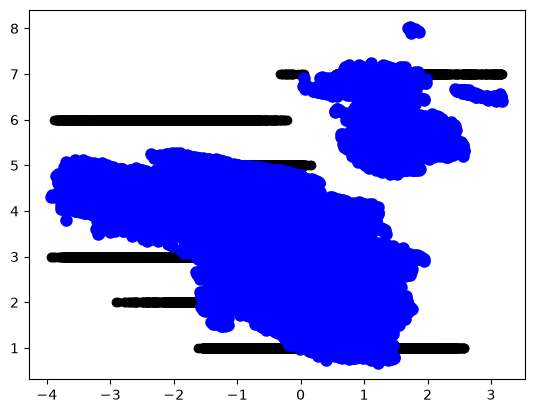

In [7]:
score = linr.score(X_test,y_test)
print(score)
plt.scatter(X_test.iloc[:, 0], y_test,  color='black')
plt.scatter(X_test.iloc[:, 0], y_pred_linr, color='blue', linewidth=3)

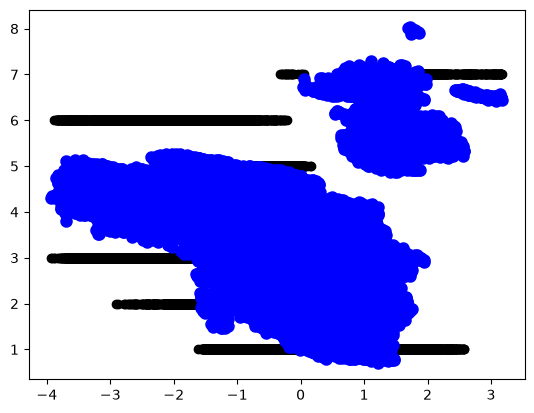

In [8]:
plt.scatter(X_test.iloc[:, 0], y_test,  color='black')
plt.scatter(X_test.iloc[:, 0], y_pred_linr_pca, color='blue', linewidth=3)

## Анализ

На диаграммах рассеяния черные точки показывают реальные значения целевой переменной, а синим цветом обозначены предсказанные на тестовой выборке линейной регрессией точки. Как видим [функции оценки качества](https://colab.research.google.com/drive/1YB8p04YCHGsBsfV70Z6J2E2tDzAXW-2T) потдвержаются здесь. Стоит упомянуть, что графики показывают зависимость от одного признака и не позволяют в полной мере оценить влияние всех признаков.

Модель часто принимает промежуточные значения между номерами классов, поскольку задача ее не в классификации. Обучение модели на двуъ выборках дает примерно одинаковые облака предсказанных на test точек, по крайней  мере их форма практически идентична. Видим, что точность модели вероятнее всего мала, поскольку синие точки в большинстве располагаются между классами, лишь частично перекрывая черные, а класс 6 и вовсе стоит особняком, не имея ни единого предсказания в свою пользу.

Таким образом, из проделанной работы можно сделать вывод о том, что линейная регрессия не подходит для применения к задаче классификации. Такой вывод полностью согласуется с теоретическими данными.

In [9]:
lgr = LogisticRegression(random_state=42, max_iter=500, solver='newton-cholesky', l1_ratio=0)
start_lgr = time.time()
lgr.fit(X_train, y_train)
time_lgr = time.time() - start_lgr

y_pred_lgr = lgr.predict(X_test)
print(f'{time_lgr}')
y_pred_lgr

66.23903441429138


array([1, 7, 5, ..., 5, 1, 1], shape=(116194,))

In [10]:
print(classification_report(y_test, y_pred_lgr))

              precision    recall  f1-score   support

           1       0.67      0.66      0.66     42367
           2       0.77      0.50      0.61     56653
           3       0.63      0.46      0.53      7151
           4       0.25      0.89      0.39       549
           5       0.10      0.75      0.17      1899
           6       0.31      0.63      0.42      3473
           7       0.40      0.90      0.55      4102

    accuracy                           0.58    116194
   macro avg       0.45      0.68      0.48    116194
weighted avg       0.69      0.58      0.61    116194



Text(0.5, 1.1, 'Confusion matrix Logistic Regression\n')

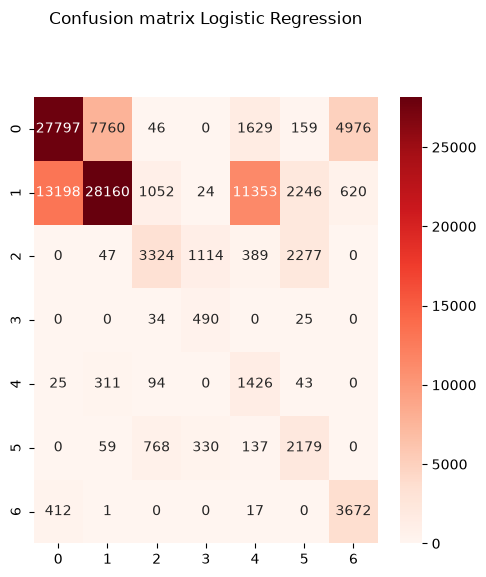

In [11]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log = confusion_matrix(y_test, y_pred_lgr)
sns.heatmap(pd.DataFrame(cnf_matrix_log), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Logistic Regression\n', y=1.1)

In [12]:
lgr_pca = LogisticRegression(random_state=42, max_iter=500)
start_lgr_pca = time.time()
lgr_pca.fit(X_train_pca, y_train_pca)
time_lgr_pca = time.time() - start_lgr_pca

y_pred_lgr_pca = lgr_pca.predict(X_test_pca)
print(f'{time_lgr_pca}')
y_pred_lgr_pca

16.923155546188354


array([1, 7, 5, ..., 5, 1, 1], shape=(116194,))

In [13]:
print(classification_report(y_test, y_pred_lgr_pca))

              precision    recall  f1-score   support

           1       0.66      0.65      0.66     42367
           2       0.77      0.49      0.59     56653
           3       0.61      0.42      0.50      7151
           4       0.22      0.82      0.34       549
           5       0.09      0.75      0.17      1899
           6       0.31      0.63      0.42      3473
           7       0.39      0.89      0.55      4102

    accuracy                           0.57    116194
   macro avg       0.44      0.67      0.46    116194
weighted avg       0.68      0.57      0.60    116194



Text(0.5, 1.1, 'Confusion matrix Logistic Regression\n')

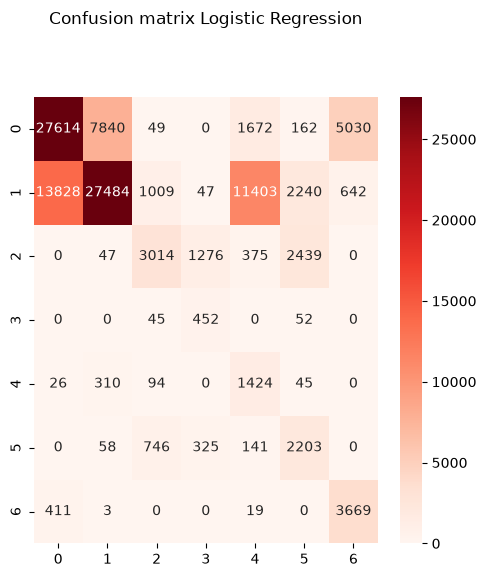

In [14]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log_pca = confusion_matrix(y_test_pca, y_pred_lgr_pca)
sns.heatmap(pd.DataFrame(cnf_matrix_log_pca), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Logistic Regression\n', y=1.1)

In [15]:
lgr_t = LogisticRegression(random_state=42, max_iter=1000, solver='newton-cholesky', l1_ratio=0)
lgr_t.fit(X_train_t, y_train_t)

y_pred_t = lgr_t.predict(X_test_t)
print(classification_report(y_test_t, y_pred_t))

              precision    recall  f1-score   support

           1       0.68      0.67      0.67     42367
           2       0.79      0.52      0.63     56653
           3       0.70      0.56      0.62      7151
           4       0.29      0.89      0.44       549
           5       0.10      0.78      0.18      1899
           6       0.34      0.66      0.45      3473
           7       0.41      0.89      0.56      4102

    accuracy                           0.60    116194
   macro avg       0.47      0.71      0.51    116194
weighted avg       0.70      0.60      0.63    116194



Text(0.5, 1.1, 'Confusion matrix Logistic Regression\n')

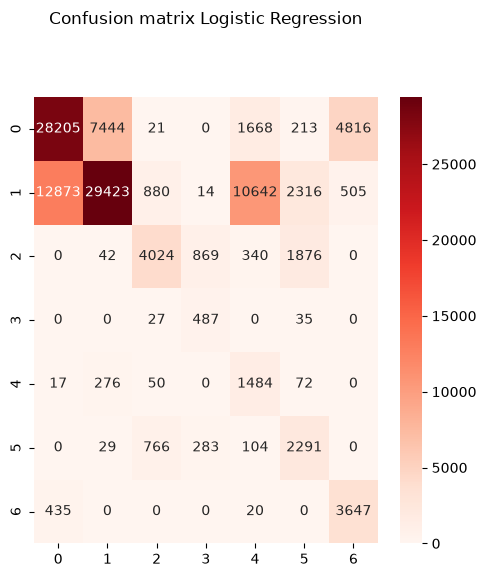

In [16]:
fig = plt.figure(figsize = (5,5))
ax = fig.gca()

cnf_matrix_log_t = confusion_matrix(y_test_t, y_pred_t)
sns.heatmap(pd.DataFrame(cnf_matrix_log_t), annot=True,cmap="Reds" , fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix Logistic Regression\n', y=1.1)

## Анализ

Провел обучение модели логистической регрессии, которая лучше подходит для задачи классификации. Однако в данном случае в качестве тестового варианта модель также была обучена на выборке до отбора признаков, предварительно прошедшей сэмплинг методом SMOTENC, как и две дургие выборки. Результаты, мягко сказать, обманули ожидания. Сразу упомяну, что, исходя из [документации Scikit-Learn](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) при оставлении параметра ``l1_ratio`` равным нулю модел будет по стандарту использовать L2-регуляризацию. В большинстве проведенных тестов данная настройка модели несколько улучшила точность предсказания, поэтому было принято решение внедрить его на ряду с оптимизацией Ньютона, заданной параметров ``solver=‘newton-cholesky’``, так как он отлично подходит для задач где количество строк значительно больше ожидаемого (n_samples >> n_features * n_classes) (см. документацию выше).

В случае с выборкой до PCA модель имеет относительно неплохие, по сравнению с ожидаемыми результаты. Общая точность моделт 0.58 - это сравнительно плохой результат, с учетом того, что в некоторых областях, судя по лекции, требуется точность около 99-100%, но для относительно простой модели логистической регресси на довольно трудном для обработки датасете это неплохой результат. Качество предсказания сильно различается в зависимости от класса. На редких имеем высокий recall (полнота) при низком precision (точность), что означает, что модель очень активно предсказывает данные классы, но часто ошибается и выдает именно их, а не исходный, что также обрушивает f1. Самые многочисленные в тестовой выборке классы 1 и 2 имеют более сбалансированные результаты. На классе 2, как самом крупном, модель здесь имеет высокую точность, но полнота при этом страдает, то есть класс отлично предсказывается, но половина случаев, выделенных под него предсказываются неверно; а на классе 2 имеем самые сбалансированные показатели - модель неплохо распознает его с результатом в 0.66. Промежуточный класс 3 имеет самый низкий recall, то есть модель пропускает больше половины объектов данного класса.

На выборке после проведения выделения признаков модель показывает себя нейтрально или чуть хуже по сравнению с первым обучением. Точность здесь снизилась на 0.01. Ни по одному классу не наблюдается улучшения. Самое сильное падение показал класс 4. Точность и полнота его предсказания упали на 0.03 и 0.07 соответственно. При этом всем модель сохранила общую тенденцию, при которой полнота поиска редких классов идет в ущерб точности предсказания, например, класс 5 за счет своей точности в 0.09 сильно просаживает результирующие метрики. 

Обучение на третьей выборке, взятой в качестве эксперимента результаты оказались самые неожиданные. Здесь общая точность модели превзошла остальные случаи и достигла 0.60, что все еще является сравнительно плохим результатом, но уже показывает улучшения. Многие классы здесь заметно укрепили свое положение, однако класс 5 все еще остается узким местом, класс 2 продолжает терять примерно половину от общих объектов.

Матрицы ошибок в целом походят друг на друга. Здесь явно видно, что модель активно путает классы 1 и 2, что суммарно дает половину всех ошибок модели. Также замечу, что класс 5 модель также активно путает со вторым, что скорее всего и ухудшает его метрики при условии, что объектов этого класса в целом мало. Отдельные классы вовсе генерируют 0 ошибок.

## 2.2 Анализ коэффициентов линейной/логистической регрессии (средний уровень)

In [17]:
lr_coefs = pd.Series(linr.coef_, index=X_train.columns)

print(f'Коэффициенты линейной регрессии на 47 признаках')

print('Наибольшее положительное влияние:')
print(lr_coefs.sort_values(ascending=False).head(3))

print('\nНаибольшее отрицательное влияние:')
print(lr_coefs.sort_values(ascending=True).head(3))

print('Все 47 признаках')
lr_coefs

Коэффициенты линейной регрессии на 47 признаках
Наибольшее положительное влияние:
Тип_почвы_37    1.939194
Тип_почвы_40    0.865541
Тип_почвы_35    0.863550
dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_21   -4.044114
Тип_почвы_22   -3.897676
Тип_почвы_25   -3.762212
dtype: float64
Все 47 признаках


Высота_над_уровнем_моря   -0.240058
Зона_дикой_природы_1      -0.641962
Зона_дикой_природы_2      -0.166101
Зона_дикой_природы_3       0.657476
Зона_дикой_природы_4       0.150587
Освещённость_3_дня        -0.054126
Освещённость_9_утра        0.058690
Тип_почвы_1               -2.412200
Тип_почвы_2               -2.514157
Тип_почвы_3               -2.794907
Тип_почвы_4               -2.864918
Тип_почвы_5               -2.044319
Тип_почвы_6               -2.280221
Тип_почвы_7               -3.140671
Тип_почвы_8               -3.251235
Тип_почвы_9               -3.600296
Тип_почвы_10              -1.811248
Тип_почвы_11              -2.466812
Тип_почвы_12              -3.352438
Тип_почвы_13              -2.148626
Тип_почвы_14              -2.170587
Тип_почвы_15              -0.649075
Тип_почвы_16              -2.050807
Тип_почвы_17              -2.141011
Тип_почвы_18              -1.265244
Тип_почвы_19              -3.250126
Тип_почвы_20              -2.869358
Тип_почвы_21              -4

In [18]:
lr_coefs_pca = pd.Series(linr_pca.coef_, index=X_train_pca.columns)

print(f'Коэффициенты линейной регрессии на 47 признаках (pca)')

print('Наибольшее положительное влияние:')
print(lr_coefs_pca.sort_values(ascending=False).head(3))

print('\nНаибольшее отрицательное влияние:')
print(lr_coefs_pca.sort_values(ascending=True).head(3))

print('Все 47 признаках (pca)')
lr_coefs_pca

Коэффициенты линейной регрессии на 47 признаках (pca)
Наибольшее положительное влияние:
Тип_почвы_37    1.915409
Тип_почвы_35    0.857519
Тип_почвы_40    0.847008
dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_21   -4.038679
Тип_почвы_22   -3.900887
Тип_почвы_25   -3.762559
dtype: float64
Все 47 признаках (pca)


Зона_дикой_природы_1   -0.641657
Зона_дикой_природы_2   -0.168912
Зона_дикой_природы_3    0.657393
Зона_дикой_природы_4    0.153176
Тип_почвы_1            -2.396804
Тип_почвы_2            -2.491785
Тип_почвы_3            -2.781714
Тип_почвы_4            -2.847392
Тип_почвы_5            -2.043328
Тип_почвы_6            -2.262689
Тип_почвы_7            -3.129687
Тип_почвы_8            -3.236793
Тип_почвы_9            -3.580148
Тип_почвы_10           -1.815823
Тип_почвы_11           -2.452942
Тип_почвы_12           -3.339492
Тип_почвы_13           -2.150588
Тип_почвы_14           -2.146021
Тип_почвы_15           -0.638413
Тип_почвы_16           -2.029820
Тип_почвы_17           -2.117742
Тип_почвы_18           -1.240947
Тип_почвы_19           -3.242635
Тип_почвы_20           -2.858747
Тип_почвы_21           -4.038679
Тип_почвы_22           -3.900887
Тип_почвы_23           -2.959411
Тип_почвы_24           -3.538068
Тип_почвы_25           -3.762559
Тип_почвы_26           -2.740159
Тип_почвы_

## Анализ

Проведем анализ коэффициентов модели линейной регрессии. В обоих вариантах можем наблюдать значительную доминацию типов почв, которые по модулю оказывают наибольшее влияние, при этом числовые признаки выглядят довольно скромно. Возможно эта ситуация свзяана с тем, что все типы почв представлены в виде бинарных признаков, в каждой строчке только в одной из типов стоит 1, поэтому можно сказать, что они сильно коррелированы между собой. 

Большие отрицательные коэффициенты на редких категориях возможно говорят о том, что модель пытается компенсировать их большими коэффициентами, чтобы дотянуть предсказание редких классов. Наиболее значимыми можно назвать как раз категориальные типы почв, зоны дикой природы 1 и 3 так как они оказывают наибольшее влияние на результат. Выделенные в 8 работе компоненты имеют довольно малые коэффициенты по сравнению с типами почв, а из-за их природы теряется интерпретируемость. 

Стоит упомянуть, что числовые признаки при этом всем не бесполезны. Хоть они и имеют сравнительно небольшие коэффициенты, нельзя забывать, что их стандартное отклонение больше, а значит влияние их коэффициентов как будто размазывается по общей картине, но все еще остается важным.

In [19]:
lgr_coefs = pd.DataFrame(lgr.coef_, index=lgr.classes_, columns=X_train.columns)

print('Коэффициенты логистической регрессии на 47 признаках\n')

for cls in lgr_coefs.index:
    print(f'Класс {cls}')
    
    row = lgr_coefs.loc[cls]
    
    print('Наибольшее положительное влияние:')
    print(row.sort_values(ascending=False).head(3))
    
    print('\nНаибольшее отрицательное влияние:')
    print(row.sort_values(ascending=True).head(3))

Коэффициенты логистической регрессии на 47 признаках

Класс 1
Наибольшее положительное влияние:
Высота_над_уровнем_моря    3.972245
Тип_почвы_9                2.651253
Тип_почвы_20               2.432839
Name: 1, dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_4    -3.566161
Тип_почвы_2    -2.386869
Тип_почвы_34   -2.233268
Name: 1, dtype: float64
Класс 2
Наибольшее положительное влияние:
Тип_почвы_12               2.322486
Тип_почвы_28               2.031474
Высота_над_уровнем_моря    1.909874
Name: 2, dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_4    -2.308586
Тип_почвы_17   -2.141663
Тип_почвы_35   -2.061198
Name: 2, dtype: float64
Класс 3
Наибольшее положительное влияние:
Тип_почвы_4             2.724502
Тип_почвы_2             2.575153
Зона_дикой_природы_3    2.118340
Name: 3, dtype: float64

Наибольшее отрицательное влияние:
Высота_над_уровнем_моря   -4.218763
Тип_почвы_20              -2.989674
Тип_почвы_33              -2.784348
Name: 3, dtype: float6

In [20]:
lgr_coefs_pca = pd.DataFrame(lgr_pca.coef_, index=lgr_pca.classes_, columns=X_train_pca.columns)

print('Коэффициенты логистической регрессии на 46признаках (pca)\n')

for cls in lgr_coefs_pca.index:
    print(f'Класс {cls}')
    
    row = lgr_coefs_pca.loc[cls]
    
    print('Наибольшее положительное влияние:')
    print(row.sort_values(ascending=False).head(3))
    
    print('\nНаибольшее отрицательное влияние:')
    print(row.sort_values(ascending=True).head(3))

Коэффициенты логистической регрессии на 46признаках (pca)

Класс 1
Наибольшее положительное влияние:
C2                      3.707631
Тип_почвы_20            2.355792
Зона_дикой_природы_1    2.133176
Name: 1, dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_4    -3.681502
Тип_почвы_34   -2.398795
Тип_почвы_37   -2.039618
Name: 1, dtype: float64
Класс 2
Наибольшее положительное влияние:
Тип_почвы_12            2.620086
Зона_дикой_природы_1    2.174112
Тип_почвы_28            1.862925
Name: 2, dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_4    -2.108835
Тип_почвы_17   -1.933862
Тип_почвы_35   -1.667591
Name: 2, dtype: float64
Класс 3
Наибольшее положительное влияние:
Тип_почвы_4    2.689282
Тип_почвы_2    2.349890
Тип_почвы_3    1.846468
Name: 3, dtype: float64

Наибольшее отрицательное влияние:
C2             -4.411938
Тип_почвы_20   -3.358776
Тип_почвы_33   -2.877069
Name: 3, dtype: float64
Класс 4
Наибольшее положительное влияние:
Зона_дикой_природы_4    3.463

In [21]:
lgr_coefs_t = pd.DataFrame(lgr_t.coef_, index=lgr_t.classes_, columns=X_train_t.columns)

print('Коэффициенты логистической регрессии на 54 признаках\n')

for cls in lgr_coefs_t.index:
    print(f'Класс {cls}')
    
    row = lgr_coefs_t.loc[cls]
    
    print('Наибольшее положительное влияние:')
    print(row.sort_values(ascending=False).head(3))
    
    print('\nНаибольшее отрицательное влияние:')
    print(row.sort_values(ascending=True).head(3))

Коэффициенты логистической регрессии на 54 признаках

Класс 1
Наибольшее положительное влияние:
Высота_над_уровнем_моря    4.477379
Тип_почвы_9                3.001759
Тип_почвы_22               2.379081
Name: 1, dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_4    -2.503825
Тип_почвы_37   -1.943291
Тип_почвы_2    -1.923148
Name: 1, dtype: float64
Класс 2
Наибольшее положительное влияние:
Тип_почвы_12    2.861751
Тип_почвы_28    2.126840
Тип_почвы_25    2.042585
Name: 2, dtype: float64

Наибольшее отрицательное влияние:
Тип_почвы_4            -1.728664
Зона_дикой_природы_3   -1.685513
Тип_почвы_17           -1.625196
Name: 2, dtype: float64
Класс 3
Наибольшее положительное влияние:
Тип_почвы_2    2.908047
Тип_почвы_4    2.698903
Тип_почвы_1    2.343138
Name: 3, dtype: float64

Наибольшее отрицательное влияние:
Высота_над_уровнем_моря   -4.631947
Тип_почвы_33              -2.452134
Тип_почвы_20              -2.174095
Name: 3, dtype: float64
Класс 4
Наибольшее положительное в

## Анализ

В отличие от линейной при логистической регрессии коэффициенты рассчитываются для каждого отдельного класса. Проанализируем полученные коэффициенты. 

Признак Высота над уровнем моря для многих классов имеет наибольшее положительное влияние, сменяясь второй компонентой в варианте выборки полученной в лабораторной работе 8. Могу предположить, что для высокогорных он имеет наибольшее положительное, а для низкогорных отрицательное.

Можно заметить, что зоны дикой пророды помогают различить классы 4 и 5, которые в линейной модели путались между собой. Типы почв все также, как ниболее широко представленные признаки продолжают доминировать во всех выборках, однако в данном случае они частично распределились по отдельным классам. Первая компонента в отличие от первой вовсе не появляется в топ 3 для каждого класса, возможно она была составлена из признаков, которые имеют слабый сигнал и из-за этого также оказывают малое влияние. 

Можно заметить что в эксперементальной выборке ситуация значительно не меняется и отброшенные признаки не входят в основном в список наболее информативных для модели. Исключением можно назвать признаки освещенности и расстояние до дорог, которые вошли с списки для классов 4 и 6.

## 2.3 Сравнение предсказаний и истинных значений (повышенный уровень)

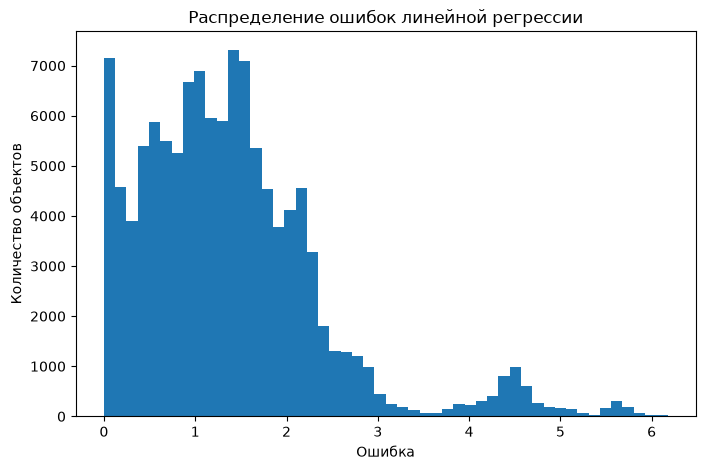

Средняя абсолютная ошибка: 1.3863702381164351
Максимальная ошибка: 6.1739530462785135
Медианная ошибка: 1.2537758493480653
Доля точных прогнозов: 18.379606520130125 %


In [22]:
y_pred_linr_class = np.clip(np.rint(y_pred_linr), y_test.min(), y_test.max()).astype(int)

linear_errors = pd.DataFrame({
    'Истинный_класс': y_test,
    'Предсказание': y_pred_linr,
    'Предсказанный_класс': y_pred_linr_class
})
linear_errors['Абсолютная_ошибка'] = (linear_errors['Истинный_класс'] - linear_errors['Предсказание']).abs()


plt.figure(figsize=(8, 5))
plt.hist(linear_errors['Абсолютная_ошибка'], bins=50)
plt.xlabel('Ошибка')
plt.ylabel('Количество объектов')
plt.title('Распределение ошибок линейной регрессии')
plt.show()

print("Средняя абсолютная ошибка:", linear_errors['Абсолютная_ошибка'].mean())

print("Максимальная ошибка:", linear_errors['Абсолютная_ошибка'].max())

print("Медианная ошибка:", linear_errors['Абсолютная_ошибка'].median())

print("Доля точных прогнозов:", (linear_errors['Предсказанный_класс'] == linear_errors['Истинный_класс']).mean() * 100, '%')

## Анализ

На графике показано распределение ошибок по модулю в линейной регрессии. Для составления графика были использованы результаты модели обученной именно на выборке без применения метода главных компонент, хотя в целом они показали себя практически идентично. Проанализируем характер ошибок, чтобы понять как именно ошибается модель. 

Абсолютная ошибка показывает насколько модель отклоняется от реального значения класса, то есть при приближении к нулю, тем точнее предсказание. Как видим наибольшая ошибка модели находятся в пределах от 0 до 3. На более чем 7 тысячах строк модель верно предсказала исходных класс, однако основная доля ошибок все еще приходтся на промежуток 2-3, то есть линейная регрессия активно путает близкие классы, что в целом логично, так как предсказывает она именно числа, а не метки классов.

Средняя и медианная ошибка подтверждают сделанные наблюдения. Здесь ошибка модели равна примерно 1-1.4, то есть модель действительно путает близкие классы. Все это в совокпуности сильно просаживает долю точных прогнозов, которая судя по статистике равняется примерно 18 процентам. Результат, мягко сказать плохой, что в очередной раз доказывает тезис о том, что базовая линейная регрессия плохо подходит для задачи классификации.

In [23]:
probs = lgr_t.predict_proba(X_test_t)
results = pd.DataFrame({
    'Исходный_класс': np.asarray(y_test_t),
    'Предсказанный_класс': y_pred_t,
    'Уверенность': probs.max(axis=1)
}, index=y_test_t.index)

results['Верно'] = (results['Исходный_класс'] == results['Предсказанный_класс'])
high_conf = results[results['Уверенность'] >= 0.9]
wrong = results[results['Исходный_класс'] != results['Предсказанный_класс']]

print("Уверенные предсказания:")
print(high_conf.head(15))

print("Ошибочные предсказания:")
print(wrong.head(15))

Уверенные предсказания:
     Исходный_класс  Предсказанный_класс  Уверенность  Верно
1                 7                    7     0.991115   True
10                1                    7     0.959444  False
21                2                    5     0.945821  False
32                2                    2     0.940296   True
35                7                    7     0.995489   True
39                2                    2     0.921764   True
41                7                    7     0.934109   True
66                2                    2     0.951923   True
75                1                    2     0.956893  False
85                7                    7     0.983596   True
99                1                    7     0.978269  False
118               1                    1     0.905419   True
119               7                    7     0.983953   True
127               2                    2     0.900289   True
137               7                    7     0.996173   True


## Анализ

В качестве модели для анализа была выбрана модель логистической регрессии обученная на выборке на момент шестой работы, так как она показала наилучший результат среди рассматриваемых. В качестве порога для уверенности модели в своем предсказании взял 0.9, то есть 90% веротяность класса.

Большинство из тех предсказаний, в которых модель была сильно уверена оказались верными, хотя из 15 выбранных 4 все таки были предсказаны не верно. Так, почти все случаи из выбранных относятся к классу 7 и классу 2, при этом модель аж 3 раза из четырех спутала класс 1. Можем сделать вывод, что высокая степень уверенности не гарантирует правильную классификацию.

Среди остальных ошибочных предсказаний есть случаи как с большой, так и с малой уверенностью модели. Например, в одном случае модель путает класс 3 с классом 4, но не уверена в своем выборе и вероятность составляет только 37%, а в другом уверенно ставит вместо класса 2 первый с 77% вероятностью. То есть ошибки могут возникать независимо от уверенности модели.

In [24]:
idx_correct = results[results['Верно']].index
idx_wrong = wrong.index

comp = pd.DataFrame({
    'Правильные предсказания': X_test_t.loc[idx_correct].mean(),
    'Ошибочные предсказания': X_test_t.loc[idx_wrong].mean()
})

comp['Разница'] = (comp['Ошибочные предсказания'] - comp['Правильные предсказания'])

comp.sort_values('Разница', key=abs, ascending=False)

,Правильные предсказания,Ошибочные предсказания,Разница
Расстояние_до_дорог,0.131492,-0.210939,-0.342432
Высота_над_уровнем_моря,0.091263,-0.142462,-0.233725
Расстояние_до_пожарных_точек,0.079306,-0.115737,-0.195043
Расстояние_до_воды_гориз,0.062066,-0.084761,-0.146827
Освещённость_3_дня,0.050154,-0.090499,-0.140653
Уклон_склона,-0.046408,0.072457,0.118865
Освещённость_полдень,0.039928,-0.066162,-0.106090
Зона_дикой_природы_1,0.487860,0.392104,-0.095755
Освещённость_9_утра,-0.026554,0.051927,0.078481
Зона_дикой_природы_3,0.408160,0.477151,0.068992


## Анализ

По таблице видно, что наиболее заметные различия между значениями признака для правильно и неправильно наблюдаются у признаков Расстояние до дорог, Высота над уровнем моря и Расстояние до пожарных точек. Их значения у ошибочно предсказанных объектов меньше и в отличие от правильно классифицированных находятся в отрицательной зоне, а у признака Уклон склона наоборот среднее значения выше у объектов с ошибочными предсказаниями. Среди категориальных явно выделяются некоторых типы почв и зоны дикой природы. Среднее значение третьей зоны выше в группе ошибочных, а у первой - ниже.

Таким образом, модель чаще ошибается на объектах с некоторыми чертами местности, как правило это малые расстояния всех видов и малая высота. Возможно сочетания этих признаков сильно затрудняют различение классов.

In [25]:
#X_all = pd.concat([X_train, X_test], axis=0, ignore_index=True)
#y_all = pd.concat([y_train, y_test], axis=0, ignore_index=True)
X_all = tt.drop(columns=['Тип_лесного_покрова'])
y_all = tt['Тип_лесного_покрова']
rs = [15, 65]
rs_results = []
rs_models = {}

for s in rs:
    X_tr_rs, X_te_rs, y_tr_rs, y_te_rs = train_test_split(X_all, y_all, test_size=0.25, random_state=s, stratify=y_all)
    
    num  = X_tr_rs.select_dtypes(include=['float64']).columns.tolist()
    cat = X_tr_rs.select_dtypes(include=['int64']).columns.tolist()
    categorical_idx = [X_tr_rs.columns.get_loc(c) for c in cat]
    c = y_tr_rs.value_counts().sort_index()
    tpc = int(c.max() * 0.2)
    strat = {cls: min(n, tpc) for cls, n  in c.items()}

    under = RandomUnderSampler(sampling_strategy=strat, random_state=42)
    smotenc = SMOTENC(
        categorical_features=categorical_idx,
        sampling_strategy='not majority',
        random_state=s,
        k_neighbors=5,
    )

    pipe = ImbPipeline([
        ('under', under),
        ('over',  smotenc),
    ])

    X_tr_rs_rs, y_tr_rs_rs = pipe.fit_resample(X_tr_rs, y_tr_rs)
    
    model = LogisticRegression(random_state=s, max_iter=500, solver='newton-cholesky')
    model.fit(X_tr_rs_rs, y_tr_rs_rs)
    pred = model.predict(X_te_rs)

    rs_models[s] = model
    rs_results.append({
        'random state': s,
        'train size': len(X_tr_rs_rs),
        'test size': len(X_te_rs),
        'accuracy': accuracy_score(y_te_rs, pred),
        'f1': f1_score(y_te_rs, pred, average='macro')
    })

rs_results = pd.DataFrame(rs_results)
rs_results

,random state,train size,test size,accuracy,f1
0,15,297423,145242,0.573815,0.472937
1,65,297423,145242,0.573560,0.470849


In [31]:
# X_all = pd.concat([X_train, X_test], axis=0, ignore_index=True)
# y_all = pd.concat([y_train, y_test], axis=0, ignore_index=True)
X_all = tt.drop(columns=['Тип_лесного_покрова'])
y_all = tt['Тип_лесного_покрова']

rs = [15, 65]
rs_results_l = []
rs_models_l = {}

for s in rs:
    X_tr_rs, X_te_rs, y_tr_rs, y_te_rs = train_test_split(X_all, y_all, test_size=0.25, random_state=s, stratify=y_all)

    num  = X_tr_rs.select_dtypes(include=['float64']).columns.tolist()
    cat = X_tr_rs.select_dtypes(include=['int64']).columns.tolist()
    categorical_idx = [X_tr_rs.columns.get_loc(c) for c in cat]
    c = y_tr_rs.value_counts().sort_index()
    tpc = int(c.max() * 0.2)
    strat = {cls: min(n, tpc) for cls, n  in c.items()}

    under = RandomUnderSampler(sampling_strategy=strat, random_state=42)
    smotenc = SMOTENC(
        categorical_features=categorical_idx,
        sampling_strategy='not majority',
        random_state=s,
        k_neighbors=5,
    )

    pipe = ImbPipeline([
        ('under', under),
        ('over',  smotenc),
    ])

    X_tr_rs_rs, y_tr_rs_rs = pipe.fit_resample(X_tr_rs, y_tr_rs)
    
    model = LinearRegression()
    model.fit(X_tr_rs_rs, y_tr_rs_rs)
    pred = model.predict(X_te_rs)

    rs_models_l[s] = model
    y_pred_linr_rs = np.clip(np.rint(pred), y_all.min(), y_all.max()).astype(int)
    rs_results_l.append({
        'random state': s,
        'train size': len(X_tr_rs),
        'test size': len(X_te_rs),
        'accuracy': accuracy_score(y_te_rs, y_pred_linr_rs),
        'f1': f1_score(y_te_rs, y_pred_linr_rs, average='macro')
    })

rs_results_l = pd.DataFrame(rs_results_l)
rs_results_l

,random state,train size,test size,accuracy,f1
0,15,435724,145242,0.178805,0.163046
1,65,435724,145242,0.183659,0.164899


In [32]:
rs_comp = pd.concat([rs_results, rs_results_l[['accuracy', 'f1']].add_suffix('_l')], axis=1)
rs_comp

,random state,train size,test size,accuracy,f1,accuracy_l,f1_l
0,15,297423,145242,0.573815,0.472937,0.178805,0.163046
1,65,297423,145242,0.573560,0.470849,0.183659,0.164899


## Анализ

При random_state = 15 точность логистической регрессии составила 0.573815, а F1-score - 0.472937. При random_state = 65 эти показатели немного увеличились и составили 0.573560 и 0.470849 соответственно. Это говорит о небольшом улучшении качества логистической регрессии после изменения разбиения данных. 

У линейной регрессии Accuracy увеличилась с 0.178805 до 0.183659, а F1-score - с 0.163046 до 0.164899. Изменения также незначительные. При этом показатели линейной регрессии заметно ниже, чем у логистической регрессии. Следовательно, для данной задачи классификации логистическая регрессия показывает значительно более высокое качество, что и было доказано уже неоднократно. В целом изменение random_state не оказало существенного влияния на результаты обеих моделей.

**Здесь, отмечу, что обучающая выборка уже прошла сэмлинг, поэтому возможно не совсем корректно объединять ее с тестовой для последующего разбиения с другим seed (СПРОСИТЬ!!!!!)**

In [28]:
coef_log = pd.DataFrame({
    'Признак': X_all.columns,
    'Коэффициенты (random_state=15)': rs_models[15].coef_[0],
    'Коэффициенты (random_state=65)': rs_models[65].coef_[0]
})

coef_log['Разница'] = (coef_log['Коэффициенты (random_state=65)'] - coef_log['Коэффициенты (random_state=15)'])

coef_lin = pd.DataFrame({
    'Признак': X_all.columns,
    'Коэффициенты (random_state=15)': rs_models_l[15].coef_,
    'Коэффициенты (random_state=65)': rs_models_l[65].coef_
})

coef_lin['Разница'] = (coef_lin['Коэффициенты (random_state=65)'] - coef_lin['Коэффициенты (random_state=15)'])

In [29]:
display(coef_log.reindex(coef_log['Разница'].abs().sort_values(ascending=False).index))

,Признак,Коэффициенты (random_state=15),Коэффициенты (random_state=65),Разница
31,Тип_почвы_18,9.778905e-01,2.403381e-02,-9.538567e-01
43,Тип_почвы_36,-6.066997e-01,-1.181143e+00,-5.744435e-01
14,Тип_почвы_26,1.661364e-01,-1.863213e-01,-3.524577e-01
37,Тип_почвы_27,1.035800e+00,7.748792e-01,-2.609212e-01
1,Тип_почвы_4,-3.422976e+00,-3.164442e+00,2.585344e-01
29,Тип_почвы_16,8.278019e-01,6.377127e-01,-1.900892e-01
16,Тип_почвы_31,8.964975e-01,7.466870e-01,-1.498105e-01
30,Тип_почвы_17,-1.382860e+00,-1.239548e+00,1.433118e-01
42,Тип_почвы_35,5.235383e-01,6.642449e-01,1.407066e-01
46,Тип_почвы_40,4.531838e-01,3.177026e-01,-1.354813e-01


In [30]:
display(coef_lin.reindex(coef_lin['Разница'].abs().sort_values(ascending=False).index))

,Признак,Коэффициенты (random_state=15),Коэффициенты (random_state=65),Разница
43,Тип_почвы_36,1.931349,2.170523,0.239174
28,Тип_почвы_15,1.763872,1.691376,-0.072496
42,Тип_почвы_35,1.963574,2.018105,0.054531
27,Тип_почвы_14,1.073235,1.027917,-0.045319
23,Тип_почвы_8,-0.283778,-0.255734,0.028044
33,Тип_почвы_21,-1.540207,-1.567134,-0.026928
30,Тип_почвы_17,0.318097,0.293096,-0.025000
19,Тип_почвы_1,-0.363172,-0.387379,-0.024207
26,Тип_почвы_11,-0.744156,-0.766060,-0.021904
41,Тип_почвы_34,-0.597326,-0.618319,-0.020993


## Анализ

После изменения random_state коэффициенты обеих моделей изменились, однако знаки в основном остались прежними. Коэффициенты логистической регрессии направления влияние в основном не поменяли. Наибольшее изменения наблюдаются у признака тип почвы 36, 9, 34. Возможно это изменение и немного увеличить точность модели, однако большинство признаков устойчивы к изменению разбиения.

В случае линейной регрессии наиболее заметные изменения коснулись коэффициентов при признаках тип почвы 34, 18, 28. При этом остальные коэффициенты изменились совсем незначительно, то есть оценки некоторвх признаков сильнее зависят от состава обучающей выборки.

**Здесь, как и выше, отмечу, что обучающая выборка уже прошла сэмлинг, поэтому возможно не совсем корректно объединять ее с тестовой для последующего разбиения с другим seed (СПРОСИТЬ!!!!!)**

## Связный текст. Вывод

Линейная регрессия предполагает линейную зависимость между признаками и целевой переменной, подбирая коэффициенты так, чтобы сделать разницу между реальными и предсказанными значениями минимальными. Логистическая регрессия же имеет другую задачу - используется для классификации и оценивает вероятность принадлежности объекта ко всем представленным классам. Линейные модели могут отлично работать, когда зависимости в используемых данных линейны или близки к ним, чтобы было проще разделить точки в пространстве. В целом, они могут быть полезны когда важна простота, а данные не имеют сложных зависимостей. Однако в ситуация, как в рассматриваемой выборке, когда зависимости нелинейны или признаки коррелированы, данные простые модели могут отрабатывать сильно хуже других. На качество итоговых моделей также могут влиять шум, выбросы и неинформативные признаки, заводящие модель в тупик. В текущей работе линейная регрессия показала себя плохо, потому что метки классов не имеют естественного числового порядка, а эта модель создана как раз для предсказания непрерывных величин. Логистическая регрессия в данном случае лучше соотвествует поставленной задаче, посколько технически выбирает один из семи представленных классов. В ходе выполнения работы было замечено, что изменение параметров разбиения данных на обучающую и тестовую выборки немного повлияло на качество обучения, однако разница была чересчур мала. Проведенный анализ неоднократно подтвердил тезис о том, что логистическая регрессия намного лучще показывает себя в задачах классификации. Линейные модели явяляются важной частью базового курса, потому что дают представление об основным принципах машинного обучения, являются отправной точкой для изучения более сложных концепций.